# Tarea 1 – Parte 1: Recolección y limpieza de noticias peruanas

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

| Campo | Valor |
|---|---|
| Opción elegida | **B – El Comercio** (350–400 noticias, ~90–100 por categoría) |
| Fecha de descarga | se registra automáticamente en la celda de configuración (`FECHA_DESCARGA`) |
| Categorías finales | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |
| URL base | https://elcomercio.pe |

**Cambio de opción (C → B), documentado.** El plan inicial era la opción C (200 + 200). En la primera ejecución, La República solo aportó **54 noticias válidas**: sus RSS y sitemaps por sección publican apenas ~25 notas cada uno (y se repiten entre sí), y su `robots.txt` prohíbe recorrer el archivo (`/archivo/*`) y la paginación de secciones (`/*/pag/*`). Para no hacer scraping agresivo ni saltarse esas reglas, se pasa a la **opción B con El Comercio**, cuyos feeds oficiales sí alcanzan el volumen pedido. Basta con cambiar `OPCION = "C"` en la configuración para volver al plan comparado.

**Fuentes utilizadas (todas permitidas en el `robots.txt` de cada medio):**

| Medio | RSS por sección | Sitemaps de noticias (complemento) |
|---|---|---|
| La República (solo opción C) | `https://larepublica.pe/rss/{seccion}.xml` | `https://larepublica.pe/sitemap/{seccion}.xml`, `https://larepublica.pe/sitemap/web/{seccion}.xml` |
| El Comercio | `https://elcomercio.pe/arc/outboundfeeds/google-news-feed/category/{seccion}/?outputType=xml` | `https://elcomercio.pe/sitemap/news/{seccion}/?outputType=xml`, `https://elcomercio.pe/sitemap/web/{seccion}/?outputType=xml` |

**Decisión metodológica.** No se recorren las portadas HTML ni las páginas paginadas de sección: el `robots.txt` de La República prohíbe las rutas `/*/pag/` y ambos medios publican canales oficiales RSS y sitemaps. Se usa:

1. **RSS** como fuente principal, porque ya trae titular, bajada (`<description>`), fecha y sección.
2. **Sitemaps de noticias** para completar el volumen, porque cada RSS solo publica las ~15–20 notas más recientes.
3. **Solo cuando falta la bajada**, una petición a la página de la nota para leer su metadato `og:description`.

Cada petición respeta el `robots.txt`, usa un `User-Agent` descriptivo, una pausa de 1,5 s y como máximo 1 reintento. Todas las respuestas se guardan en `datos/raw/` y se reutilizan si el notebook se vuelve a ejecutar, de modo que una segunda ejecución no vuelve a golpear los servidores.

In [2]:
%pip install requests beautifulsoup4 lxml pandas plotly kaleido

Note: you may need to restart the kernel to use updated packages.


## 0. Configuración

In [3]:
import hashlib, json, random, re, time, unicodedata
from datetime import date, datetime
from pathlib import Path
from urllib.parse import urlparse, urlunparse
from urllib import robotparser

import pandas as pd
import requests
from bs4 import BeautifulSoup
import plotly.express as px
import plotly.io as pio

# Interactivo en VS Code + imagen PNG de respaldo para que los gráficos se vean en GitHub
# (GitHub no ejecuta el JavaScript de Plotly). Requiere `kaleido`.
pio.renderers.default = "plotly_mimetype+png"

pd.set_option("display.max_colwidth", 120)
random.seed(42)

FECHA_DESCARGA = date.today().isoformat()
USER_AGENT = ("TareaDataSciencePython/1.0 (proyecto academico; clasificacion de titulares; "
              "1 peticion cada 1.5 s)")
PAUSA_SEG = 1.5          # pausa entre peticiones
MAX_REINTENTOS = 1       # máximo 1 reintento
OPCION = "B"             # "B" = solo El Comercio | "C" = comparada (La República + El Comercio)
OBJETIVO = 100 if OPCION == "B" else 50   # tope por medio y categoría: B -> 4 x 100 = 400
MARGEN = 15              # recolectamos algo más para absorber duplicados y descartes

DATOS = Path("datos"); RAW = DATOS / "raw"; CACHE = RAW / "cache"
for p in (DATOS, RAW, CACHE):
    p.mkdir(parents=True, exist_ok=True)

print("Fecha de descarga:", FECHA_DESCARGA)

Fecha de descarga: 2026-10-19


In [4]:
FUENTES = {
    "La Republica": {
        "base": "https://larepublica.pe",
        # sección del feed -> categoría final
        "secciones": {"politica": "politica", "economia": "economia",
                      "deportes": "deportes", "ciencia": "ciencia_tecnologia"},
        "rss": "https://larepublica.pe/rss/{sec}.xml",
        "sitemaps": ["https://larepublica.pe/sitemap/{sec}.xml",
                     "https://larepublica.pe/sitemap/web/{sec}.xml"],
        # fuentes generales: sirven para completar y generan descartes reales (otras secciones)
        "generales": ["https://larepublica.pe/rss/home.xml",
                      "https://larepublica.pe/sitemap/noticias.xml"],
    },
    "El Comercio": {
        "base": "https://elcomercio.pe",
        "secciones": {"politica": "politica", "economia": "economia",
                      "deporte-total": "deportes", "tecnologia": "ciencia_tecnologia"},
        "rss": "https://elcomercio.pe/arc/outboundfeeds/google-news-feed/category/{sec}/?outputType=xml",
        "sitemaps": ["https://elcomercio.pe/sitemap/news/{sec}/?outputType=xml",
                     "https://elcomercio.pe/sitemap/web/{sec}/?outputType=xml"],
        "generales": ["https://elcomercio.pe/arc/outboundfeeds/google-news-feed/?outputType=xml"],
    },
}
if OPCION == "B":
    FUENTES = {"El Comercio": FUENTES["El Comercio"]}
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
print("Medios:", list(FUENTES))

Medios: ['El Comercio']


## 1. Cliente HTTP responsable

`robots.txt` → pausa → petición → como máximo 1 reintento → copia cruda en disco. Si la copia ya existe, se lee del disco y no se hace ninguna petición.

In [5]:
SESION = requests.Session()
SESION.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "es-PE,es;q=0.9"})
_ROBOTS = {}
LOG = []   # bitácora de peticiones

def permitido(url):
    host = "{0.scheme}://{0.netloc}".format(urlparse(url))
    if host not in _ROBOTS:
        rp = robotparser.RobotFileParser(host + "/robots.txt")
        try:
            r = SESION.get(host + "/robots.txt", timeout=20)
            rp.parse(r.text.splitlines())
        except requests.RequestException:
            rp.parse([])            # si no se puede leer, no bloquea
        _ROBOTS[host] = rp
        time.sleep(PAUSA_SEG)
    return _ROBOTS[host].can_fetch(USER_AGENT, url)

def _ruta_cache(url, ext):
    return CACHE / (hashlib.md5(url.encode()).hexdigest() + ext)

def descargar(url, ext=".xml"):
    # Devuelve el texto de la URL (o None). Usa la caché cruda si existe.
    ruta = _ruta_cache(url, ext)
    if ruta.exists():
        LOG.append({"url": url, "estado": "cache"})
        return ruta.read_text(encoding="utf-8")
    if not permitido(url):
        LOG.append({"url": url, "estado": "bloqueado_robots"})
        return None
    for intento in range(1 + MAX_REINTENTOS):
        time.sleep(PAUSA_SEG)
        try:
            r = SESION.get(url, timeout=25)
            if r.status_code == 200:
                r.encoding = r.encoding or "utf-8"
                ruta.write_text(r.text, encoding="utf-8")
                LOG.append({"url": url, "estado": 200})
                return r.text
            LOG.append({"url": url, "estado": r.status_code})
            if r.status_code in (403, 404, 410):
                return None          # no tiene sentido reintentar
        except requests.RequestException as e:
            LOG.append({"url": url, "estado": type(e).__name__})
    return None

## 2. Funciones de extracción

In [6]:
def limpiar_texto(t):
    if t is None:
        return ""
    t = BeautifulSoup(str(t), "html.parser").get_text(" ")
    t = unicodedata.normalize("NFC", t)
    return re.sub(r"\s+", " ", t).strip()

def recortar_bajada(t, max_chars=300):
    # La bajada debe ser breve (1-2 líneas): cortamos en la 2.ª oración o a 300 caracteres.
    t = limpiar_texto(t)
    oraciones = re.split(r"(?<=[.!?])\s+", t)
    t = " ".join(oraciones[:2])
    return t if len(t) <= max_chars else t[:max_chars].rsplit(" ", 1)[0] + "…"

def seccion_desde_url(url):
    # 'larepublica.pe/deportes/2026/10/03/...'      -> 'deportes'
    # 'elcomercio.pe/tecnologia/robotica/...-noticia/' -> 'tecnologia/robotica'
    segs = [s for s in urlparse(url).path.split("/") if s]
    out = []
    for s in segs[:-1]:
        if s.isdigit():
            break
        out.append(s)
    return "/".join(out) if out else "(sin_seccion)"

def normalizar_url(url):
    p = urlparse(url.strip())
    return urlunparse((p.scheme, p.netloc.lower(), p.path, "", "", ""))

def _hijo(nodo, nombre):
    # Busca un hijo por nombre local, ignorando el prefijo de namespace (news:, content:, ...).
    if nodo is None:
        return None
    return nodo.find(lambda tag: tag.name.split(":")[-1] == nombre)

def parsear_rss(xml, medio, fuente):
    soup = BeautifulSoup(xml, "xml")
    filas = []
    for it in soup.find_all("item"):
        link = limpiar_texto(_hijo(it, "link").text if _hijo(it, "link") else "")
        bajada = recortar_bajada(_hijo(it, "description").text if _hijo(it, "description") else "")
        if not bajada:
            # Plan B: primer párrafo del cuerpo (content:encoded), saltando la lista de "notas relacionadas".
            enc = _hijo(it, "encoded")
            if enc is not None:
                cuerpo = BeautifulSoup(enc.text, "html.parser")
                for ul in cuerpo.find_all("ul"):
                    ul.decompose()
                p = cuerpo.find("p")
                bajada = recortar_bajada(p.get_text(" ") if p else "")
        filas.append({
            "titular": limpiar_texto(_hijo(it, "title").text if _hijo(it, "title") else ""),
            "bajada": bajada,
            "medio": medio,
            "url": link,
            "fecha_raw": limpiar_texto(_hijo(it, "pubDate").text if _hijo(it, "pubDate") else ""),
            "fuente": fuente,
        })
    return filas

def parsear_sitemap(xml, medio, fuente):
    # Devuelve (filas, sitemaps_hijos). Soporta <urlset> y <sitemapindex>.
    soup = BeautifulSoup(xml, "xml")
    if soup.find("sitemapindex"):
        return [], [limpiar_texto(s.find("loc").text) for s in soup.find_all("sitemap") if s.find("loc")]
    filas = []
    for u in soup.find_all("url"):
        loc = u.find("loc")
        if loc is None:
            continue
        noticia = _hijo(u, "news")
        titulo = _hijo(noticia, "title")
        fecha = _hijo(noticia, "publication_date") or u.find("lastmod")
        filas.append({
            "titular": limpiar_texto(titulo.text) if titulo else "",
            "bajada": "",                    # el sitemap no trae bajada: se completa luego
            "medio": medio,
            "url": limpiar_texto(loc.text),
            "fecha_raw": limpiar_texto(fecha.text) if fecha else "",
            "fuente": fuente,
        })
    return filas, []

def leer_sitemap(url, medio, fuente, profundidad=0):
    xml = descargar(url)
    if not xml:
        return []
    filas, hijos = parsear_sitemap(xml, medio, fuente)
    if profundidad < 1:
        for h in hijos:
            filas += leer_sitemap(h, medio, fuente, profundidad + 1)
    return filas

def metadatos_nota(url):
    # og:title / og:description de la página de la nota (solo si falta algún dato).
    html = descargar(url, ext=".html")
    if not html:
        return "", ""
    soup = BeautifulSoup(html, "html.parser")
    def meta(*claves):
        for k in claves:
            m = soup.find("meta", attrs={"property": k}) or soup.find("meta", attrs={"name": k})
            if m and m.get("content"):
                return m["content"]
        return ""
    return limpiar_texto(meta("og:title", "twitter:title")), recortar_bajada(meta("og:description", "description"))

## 3. Extracción

Para cada medio y sección: primero el RSS; si no alcanza `OBJETIVO + MARGEN` notas únicas, se completa con los sitemaps y después con las fuentes generales. Las notas que vienen de otras secciones (Mundo, Espectáculos, etc.) **no** se fuerzan a una categoría: se descartan en la limpieza y se reportan.

> La primera ejecución tarda unos 10–15 minutos por las pausas de 1,5 s. Las siguientes son casi instantáneas gracias a la caché.

In [7]:
def _cat_de_url(url, mapeo_sec):
    return mapeo_sec.get(seccion_desde_url(url).split("/")[0])

filas = []
for medio, cfg in FUENTES.items():
    mapeo_sec = cfg["secciones"]
    for sec in mapeo_sec:
        filas += parsear_rss(descargar(cfg["rss"].format(sec=sec)) or "", medio, f"rss:{sec}")
    for sec, cat in mapeo_sec.items():
        unicas = {normalizar_url(f["url"]) for f in filas
                  if f["medio"] == medio and _cat_de_url(f["url"], mapeo_sec) == cat}
        if len(unicas) < OBJETIVO + MARGEN:
            for sm in cfg["sitemaps"]:
                filas += leer_sitemap(sm.format(sec=sec), medio, f"sitemap:{sec}")
    for g in cfg["generales"]:
        filas += (parsear_rss(descargar(g), medio, "rss:general") if "rss" in g or "feed" in g
                  else leer_sitemap(g, medio, "sitemap:general"))

df_crudo = pd.DataFrame(filas)
df_crudo["seccion_original"] = df_crudo["url"].map(seccion_desde_url)
df_crudo.to_csv(RAW / f"noticias_crudas_{FECHA_DESCARGA}.csv", index=False)
print("Filas crudas:", len(df_crudo))
df_crudo.groupby(["medio", "fuente"]).size().rename("filas").to_frame()

/var/folders/b7/js00pg5x37zbggvjbftff0v00000gn/T/ipykernel_77486/3018186948.py:4: MarkupResemblesLocatorWarning: The input passed in on this line looks more like a URL than HTML or XML.

If you meant to use Beautiful Soup to parse the web page found at a certain URL, then something has gone wrong. You should use an Python package like 'requests' to fetch the content behind the URL. Once you have the content as a string, you can feed that string into Beautiful Soup.

However, if you want to parse some data that happens to look like a URL, then nothing has gone wrong: you are using Beautiful Soup correctly, and this warning is spurious and can be filtered. To make this warning go away, run this code before calling the BeautifulSoup constructor:

    from bs4 import MarkupResemblesLocatorWarning
    import warnings

    warnings.filterwarnings("ignore", category=MarkupResemblesLocatorWarning)
    
  t = BeautifulSoup(str(t), "html.parser").get_text(" ")


Filas crudas: 1033


filas
medio       fuente                      
El Comercio rss:deporte-total         84
            rss:economia              12
            rss:general              100
            rss:politica              22
            rss:tecnologia            15
            sitemap:deporte-total    200
            sitemap:economia         200
            sitemap:politica         200
            sitemap:tecnologia       200

### 3.1 Completar bajadas faltantes

Las filas que vienen del sitemap no traen bajada. Para no hacer peticiones innecesarias, solo se completan las notas que pertenecen a las 4 secciones válidas y que hacen falta para llegar al objetivo (prioridad: las más recientes).

In [8]:
df_crudo["url_norm"] = df_crudo["url"].map(normalizar_url)
df_crudo["fecha"] = (pd.to_datetime(df_crudo["fecha_raw"], utc=True, errors="coerce", format="mixed")
                       .dt.tz_convert("America/Lima"))
mapeo_global = {k: v for cfg in FUENTES.values() for k, v in cfg["secciones"].items()}
df_crudo["cat_tentativa"] = df_crudo["seccion_original"].str.split("/").str[0].map(mapeo_global)

# Priorizamos la fila de RSS (trae bajada) frente a la del sitemap para la misma URL
df_crudo["tiene_bajada"] = df_crudo["bajada"].fillna("").str.len() > 0
base = (df_crudo.sort_values(["tiene_bajada", "fecha"], ascending=False)
                .drop_duplicates("url_norm"))

pendientes = []
for (medio, cat), g in base.dropna(subset=["cat_tentativa"]).groupby(["medio", "cat_tentativa"]):
    g = g.sort_values("fecha", ascending=False).head(OBJETIVO + MARGEN)
    pendientes += g.loc[~g["tiene_bajada"] | (g["titular"] == "")].index.tolist()

print(f"Notas a completar con og:description: {len(pendientes)} "
      f"(~{len(pendientes) * PAUSA_SEG / 60:.1f} min si no están en caché)")
for i in pendientes:
    titulo, bajada = metadatos_nota(base.at[i, "url"])
    if not base.at[i, "titular"]:
        base.at[i, "titular"] = titulo
    if not base.at[i, "bajada"]:
        base.at[i, "bajada"] = bajada

# Volvemos a unir con todas las filas crudas (incluye duplicados) para que la limpieza los reporte
completadas = base.set_index("url_norm")[["titular", "bajada"]]
df_crudo = df_crudo.join(completadas, on="url_norm", rsuffix="_ok")
df_crudo["titular"] = df_crudo["titular_ok"].where(df_crudo["titular_ok"].fillna("") != "", df_crudo["titular"])
df_crudo["bajada"] = df_crudo["bajada_ok"].where(df_crudo["bajada_ok"].fillna("") != "", df_crudo["bajada"])
df_crudo = df_crudo.drop(columns=["titular_ok", "bajada_ok"])

pd.DataFrame(LOG)["estado"].value_counts().rename("peticiones").to_frame()

Notas a completar con og:description: 256 (~6.4 min si no están en caché)


,peticiones
estado,
cache,161
200,108


## 4. Limpieza y normalización

### 4.1 Tabla de mapeo `seccion_original` → categoría final

In [9]:
MAPEO_SECCION = {            # primer nivel de la URL -> categoría oficial
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",          # La República
    "deporte-total": "deportes",     # El Comercio
    "ciencia": "ciencia_tecnologia", # La República
    "tecnologia": "ciencia_tecnologia",  # El Comercio (incluye ciencias, ecologia, ia, ...)
}

tabla_mapeo = (df_crudo.assign(etiqueta=df_crudo["seccion_original"].str.split("/").str[0]
                                .map(MAPEO_SECCION).fillna("— descartada —"))
               .groupby(["medio", "seccion_original", "etiqueta"]).size()
               .rename("n_noticias").reset_index()
               .sort_values(["etiqueta", "medio", "n_noticias"], ascending=[True, True, False]))
tabla_mapeo

,medio,seccion_original,etiqueta,n_noticias
58,El Comercio,tecnologia/actualidad,ciencia_tecnologia,78
63,El Comercio,tecnologia/inteligencia-artificial,ciencia_tecnologia,41
60,El Comercio,tecnologia/ciencias,ciencia_tecnologia,24
59,El Comercio,tecnologia/ciberseguridad,ciencia_tecnologia,15
68,El Comercio,tecnologia/videojuegos,ciencia_tecnologia,13
...,...,...,...,...
47,El Comercio,respuestas/argentina,— descartada —,1
50,El Comercio,respuestas/cuando,— descartada —,1
51,El Comercio,respuestas/farandula,— descartada —,1
54,El Comercio,respuestas/que,— descartada —,1


### 4.2 Filtros de limpieza y reporte de descartes

In [10]:
descartes = []
def descartar(df, mascara, motivo):
    d = df[mascara].copy(); d["motivo"] = motivo
    descartes.append(d)
    return df[~mascara]

df = df_crudo.copy()
df["titular"] = df["titular"].fillna("").map(limpiar_texto)
df["bajada"] = df["bajada"].fillna("").map(limpiar_texto)
df["etiqueta"] = df["seccion_original"].str.split("/").str[0].map(MAPEO_SECCION)

df = descartar(df, df["titular"].str.len() == 0, "titular vacío")
df = descartar(df, df["url_norm"].duplicated(keep="first"), "URL duplicada")
df = descartar(df, df["etiqueta"].isna(), "sección fuera de las 4 categorías")
df = descartar(df, df.duplicated(["medio", "titular"], keep="first"), "titular repetido en el mismo medio")
df = descartar(df, df["fecha"].isna(), "sin fecha de publicación")

# Balanceo: como máximo OBJETIVO noticias (las más recientes) por medio x categoría
df = df.sort_values("fecha", ascending=False)
excedente = df.groupby(["medio", "etiqueta"]).cumcount() >= OBJETIVO
df = descartar(df, excedente, f"excedente (tope de {OBJETIVO} por medio y categoría)")

df_desc = pd.concat(descartes)
print(f"Filas crudas: {len(df_crudo)} | conservadas: {len(df)} | descartadas: {len(df_desc)}")
df_desc.groupby(["motivo", "medio"]).size().unstack(fill_value=0)

Filas crudas: 1033 | conservadas: 383 | descartadas: 650


medio,El Comercio
motivo,
URL duplicada,558
sección fuera de las 4 categorías,92


In [11]:
# Ejemplos de noticias descartadas por estar fuera de las 4 categorías (no se inventa una 5.ª)
(df_desc[df_desc["motivo"] == "sección fuera de las 4 categorías"]
   .groupby("seccion_original").size().sort_values(ascending=False).head(15)
   .rename("n").to_frame())

,n
seccion_original,
mag/usa/local-us,8
mag/respuestas,8
lima/sucesos,7
opinion/columnistas,6
respuestas,5
mundo/latinoamerica,4
mag/usa/en-vivo-us,4
respuestas/mexico,4
ecdata,4


In [12]:
conteo = df.groupby(["medio", "etiqueta"]).size().unstack(fill_value=0)
conteo["total"] = conteo.sum(axis=1)
faltan = (OBJETIVO - conteo[CATEGORIAS]).clip(lower=0)
if faltan.values.sum() > 0:
    print(f"⚠️ Celdas por debajo de {OBJETIVO} (es aceptable si el total es 350+; documéntalo en el README):")
    print(faltan[faltan.sum(axis=1) > 0])
print("Bajadas vacías:", (df["bajada"] == "").sum())
print(f"TOTAL: {len(df)} noticias", "✅ cumple 350+" if len(df) >= 350 else "❌ menos de 350")
conteo

⚠️ Celdas por debajo de 100 (es aceptable si el total es 350+; documéntalo en el README):
etiqueta     politica  economia  deportes  ciencia_tecnologia
medio                                                        
El Comercio         9         1         2                   5
Bajadas vacías: 0
TOTAL: 383 noticias ✅ cumple 350+


etiqueta,ciencia_tecnologia,deportes,economia,politica,total
medio,,,,,
El Comercio,95,98,99,91,383


### 4.3 Verificación de URLs funcionales (muestra aleatoria)

In [13]:
muestra = df.sample(min(15, len(df)), random_state=42)
estados = []
for u in muestra["url"]:
    time.sleep(PAUSA_SEG)
    try:
        r = SESION.head(u, timeout=20, allow_redirects=True)
        estados.append(r.status_code)
    except requests.RequestException as e:
        estados.append(type(e).__name__)
muestra = muestra.assign(http=estados)[["medio", "titular", "url", "http"]]
print(f"URLs con HTTP 200: {(muestra['http'] == 200).sum()}/{len(muestra)}")
muestra

URLs con HTTP 200: 15/15


,medio,titular,url,http
191,El Comercio,Reinfo: Decano del Colegio de Abogados de Loreto afirma que Ejecutivo y Congreso no responden demanda contra ampliación,https://elcomercio.pe/politica/actualidad/decano-del-colegio-de-abogados-de-loreto-afirma-que-el-ejecutivo-y-congres...,200
415,El Comercio,El Niño retrasaría la recuperación económica del Perú hasta la segunda mitad de 2027: las cifras del impacto,https://elcomercio.pe/economia/el-nino-retrasaria-la-recuperacion-economica-del-peru-hasta-la-segunda-mitad-de-2027-...,200
431,El Comercio,Precio del dólar del lunes 12 de octubre: a cuánto cerró el tipo de cambio,https://elcomercio.pe/economia/mercados/precio-del-dolar-en-peru-hoy-cuanto-esta-el-dolar-este-lunes-12-de-octubre-t...,200
778,El Comercio,Científicos descubren cómo predecir cuándo una inteligencia artificial dará respuestas peligrosas,https://elcomercio.pe/tecnologia/inteligencia-artificial/cientificos-descubren-como-predecir-cuando-una-inteligencia...,200
58,El Comercio,"Gol de Andy Polo: Universitario vence 2-0 a Alianza Atlético por el Torneo Clausura, Liga 1 | VIDEO",https://elcomercio.pe/deporte-total/futbol-peruano/video-gol-de-andy-polo-hoy-con-universitario-vs-alianza-atletico-...,200
821,El Comercio,Noruega estudia prohibir temporalmente las gafas inteligentes,https://elcomercio.pe/tecnologia/gadgets/noruega-estudia-prohibir-temporalmente-las-gafas-inteligentes-noticia/,200
41,El Comercio,VIDEO: Universitario goleó 4-1 a Alianza Atlético y sigue en la pelea por el Torneo Clausura,https://elcomercio.pe/deporte-total/futbol-peruano/video-liga-1-max-en-vivo-gratis-futbol-libre-tv-universitario-vs-...,200
100,El Comercio,A falta de una etapa: Eduardo Castro mantiene liderato de Caminos del Inca seguido de cerca por André Martínez,https://elcomercio.pe/deporte-total/caminos-del-inca-2026-eduardo-castro-mantiene-liderato-tras-quinta-etapa-cusco-p...,200
824,El Comercio,"Las empresas de IA son incapaces de controlar sus modelos, alerta un exinvestigador de OpenAI",https://elcomercio.pe/tecnologia/inteligencia-artificial/las-empresas-de-ia-son-incapaces-de-controlar-sus-modelos-a...,200
391,El Comercio,"Luis Felipe Gazitúa, del Consejo Empresarial Chileno- Peruano: “El principal destino de la inversión extranjera chil...",https://elcomercio.pe/economia/luis-felipe-gazitua-el-principal-destino-de-la-inversion-extranjera-chilena-es-el-per...,200


## 5. Análisis exploratorio (Plotly Express)

In [14]:
df["fecha_dia"] = df["fecha"].dt.strftime("%Y-%m-%d")
df["long_titular"] = df["titular"].str.len()
COLORES = {"La Republica": "#C0392B", "El Comercio": "#1F4E79"}

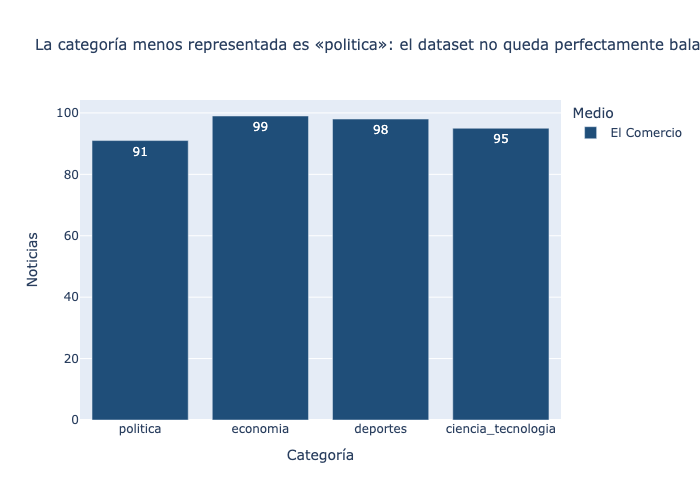

In [15]:
# Gráfico 1 – distribución por categoría y medio
g1 = df.groupby(["etiqueta", "medio"]).size().rename("n").reset_index()
balanceado = g1["n"].nunique() == 1
titulo1 = (f"El dataset está balanceado: {g1['n'].iloc[0]} noticias por categoría"
           if balanceado else
           f"La categoría menos representada es «{g1.groupby('etiqueta')['n'].sum().idxmin()}»: "
           "el dataset no queda perfectamente balanceado")
fig1 = px.bar(g1, x="etiqueta", y="n", color="medio", barmode="group", text="n",
              color_discrete_map=COLORES, category_orders={"etiqueta": CATEGORIAS},
              labels={"etiqueta": "Categoría", "n": "Noticias", "medio": "Medio"},
              title=titulo1)
fig1.update_layout(title_font_size=15)
fig1.show()

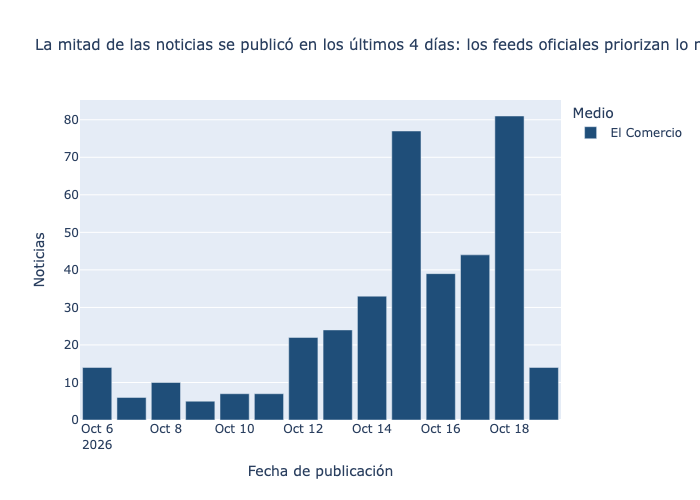

In [16]:
# Gráfico 2 – distribución en el tiempo
g2 = df.groupby(["fecha_dia", "medio"]).size().rename("n").reset_index()
if df["medio"].nunique() > 1:
    rango = df.groupby("medio")["fecha"].agg(["min", "max"])
    dias = (rango["max"] - rango["min"]).dt.days + 1
    titulo2 = (f"{dias.idxmax()} necesita {dias.max()} días para reunir sus noticias "
               f"vs. {dias.min()} días de {dias.idxmin()}: publica menos en estas secciones")
else:
    ultimo = df["fecha"].max()
    dias_mitad = int((ultimo - df["fecha"].median()).days) + 1
    titulo2 = (f"La mitad de las noticias se publicó en los últimos {dias_mitad} días: "
               "los feeds oficiales priorizan lo más reciente")
fig2 = px.bar(g2, x="fecha_dia", y="n", color="medio", color_discrete_map=COLORES,
              labels={"fecha_dia": "Fecha de publicación", "n": "Noticias", "medio": "Medio"},
              title=titulo2)
fig2.update_layout(title_font_size=15, bargap=0.15)
fig2.show()

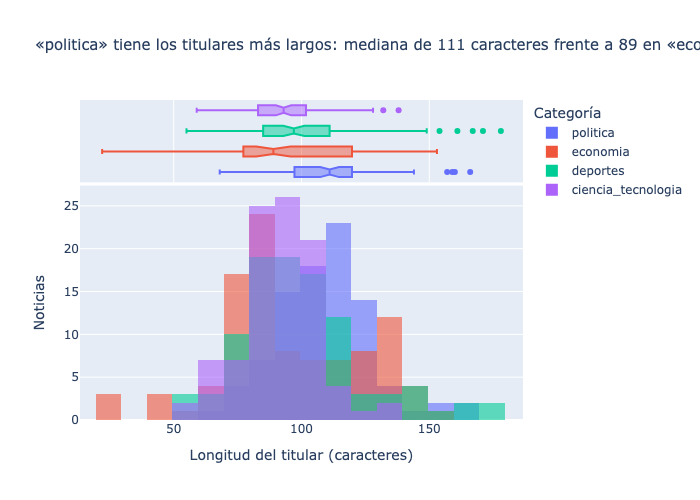

In [17]:
# Gráfico 3 – histograma de longitud de titulares
grupo = "medio" if df["medio"].nunique() > 1 else "etiqueta"
med = df.groupby(grupo)["long_titular"].median()
largo, corto = med.idxmax(), med.idxmin()
titulo3 = (f"«{largo}» tiene los titulares más largos: mediana de {med.max():.0f} caracteres "
           f"frente a {med.min():.0f} en «{corto}»")
fig3 = px.histogram(df, x="long_titular", color=grupo, nbins=30, barmode="overlay",
                    opacity=0.6, marginal="box",
                    color_discrete_map=COLORES if grupo == "medio" else None,
                    category_orders={"etiqueta": CATEGORIAS},
                    labels={"long_titular": "Longitud del titular (caracteres)", "medio": "Medio",
                            "etiqueta": "Categoría"},
                    title=titulo3)
fig3.update_layout(title_font_size=15, yaxis_title="Noticias")
fig3.show()

In [18]:
# Resumen numérico que respalda los títulos
df.groupby(["medio", "etiqueta"])["long_titular"].median().unstack().round(0)

etiqueta,ciencia_tecnologia,deportes,economia,politica
medio,,,,
El Comercio,93.0,97.0,89.0,111.0


## 6. Validación: titulares más largos y más cortos

In [19]:
cols = ["medio", "etiqueta", "long_titular", "titular"]
print("5 titulares MÁS LARGOS")
display(df.nlargest(5, "long_titular")[cols])
print("5 titulares MÁS CORTOS")
display(df.nsmallest(5, "long_titular")[cols])
print(f"Rango del histograma: {df['long_titular'].min()} – {df['long_titular'].max()} caracteres")

5 titulares MÁS LARGOS


,medio,etiqueta,long_titular,titular
63,El Comercio,deportes,178,"“El jugador peruano tiene un déficit grande en nutrición y táctica que resuelve a los 20 años, eso en Argentina es a..."
64,El Comercio,deportes,171,El furioso “Que se dedique a administrar” de Guede a Franco Velazco y un Quevedo que reconquistó a Comando Sur: Lo q...
114,El Comercio,deportes,167,“Creo que puedo llegar a un top 3 sin que nadie se quede botado”: Raúl ‘Mono’ Orlandini le responde a El Comercio so...
199,El Comercio,politica,166,"Keiko Fujimori sobre Álvaro Vargas Llosa: “Confío en que su trayectoria, experiencia y compromiso contribuirán a for..."
546,El Comercio,deportes,161,"“Cuando muchos nos abandonaron, los jugadores no dejaron de creer”: Mosquera y la filosofía que conquistó al vestuar..."


5 titulares MÁS CORTOS


,medio,etiqueta,long_titular,titular
398,El Comercio,economia,22,Invocación por el Perú
30,El Comercio,economia,23,AlaCena no tiene precio
360,El Comercio,economia,24,IA y Sandbox regulatorio
412,El Comercio,economia,41,La evolución de la confianza en los pagos
31,El Comercio,economia,43,Premio Nobel de Economía: la macro es micro


Rango del histograma: 22 – 178 caracteres


**Lectura de la validación:** los extremos coinciden con las colas del histograma. Los titulares más largos suelen ser notas de servicio o en vivo ("EN VIVO: …, hora y canal …"), y los más cortos, nombres propios o frases de impacto. Ninguno es un error de extracción (texto cortado, HTML residual o titular vacío).

*(Revisa la salida y ajusta este párrafo si tus extremos muestran otro patrón.)*

## 7. Exportación

In [20]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
final = df.assign(fecha=df["fecha"].dt.strftime("%Y-%m-%d"))[COLUMNAS].reset_index(drop=True)
assert final.columns.tolist() == COLUMNAS
assert final["url"].is_unique and (final["titular"].str.len() > 0).all()
assert set(final["etiqueta"]) <= set(CATEGORIAS)

final.to_csv(DATOS / "noticias.csv", index=False, encoding="utf-8")
pd.DataFrame(LOG).to_csv(RAW / f"log_peticiones_{FECHA_DESCARGA}.csv", index=False)
print("df.shape:", final.shape)
final.head(5)

df.shape: (383, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Canales de televisión para mirar FC Barcelona vs. PSG: hora del partido por la jornada 3 de la UEFA Champions League,Consulta los canales de TV y plataformas online para ver el partido entre Barcelona vs. PSG el martes 20 de octubre ...,El Comercio,deporte-total/espana,https://elcomercio.pe/deporte-total/espana/donde-ver-barcelona-vs-psg-en-vivo-gratis-por-champions-league-a-que-hora...,2026-10-19,deportes
1,¿Cambia el fútbol por la NFL? Mbappé muestra sus dotes en el fútbol americano con Bijan Robinson | VIDEO,La estrella del Real Madrid se puso el casco y las hombreras de los Atlanta Falcons durante un entrenamiento con el ...,El Comercio,deporte-total/futbol-mundial,https://elcomercio.pe/deporte-total/futbol-mundial/cambia-el-futbol-por-la-nfl-kylian-mbappe-muestra-sus-dotes-en-el...,2026-10-19,deportes
2,“Una oportunidad para reconocer todo lo que el club representa para sus hinchas”: Alianza presenta edición especial ...,La edición especial vuelve durante octubre para acompañar a la hinchada blanquiazul en un año que marca un nuevo cap...,El Comercio,deporte-total/futbol-peruano,https://elcomercio.pe/deporte-total/futbol-peruano/alianza-presenta-edicion-especial-por-sus-125-anos-una-oportunida...,2026-10-19,deportes
3,Como en sus mejores tiempos: el lujo de Neymar ante Hulk que se hizo viral | VIDEO,El astro brasileño protagonizó una jugada de lujo en el Maracaná y ayudó a su equipo a imponerse por 2-1 en el Brasi...,El Comercio,deporte-total/futbol-mundial,https://elcomercio.pe/deporte-total/futbol-mundial/como-en-sus-mejores-tiempos-el-lujo-de-neymar-ante-hulk-que-se-hi...,2026-10-19,deportes
4,“Es el mejor de todos los tiempos”: La curiosa reacción de Luis Enrique al hablar de Messi y Lamine,"El entrenador del PSG elogió el crecimiento de la joven estrella del Barcelona, pero consideró que compararlo con el...",El Comercio,deporte-total/futbol-mundial,https://elcomercio.pe/deporte-total/futbol-mundial/es-el-mejor-de-todos-los-tiempos-la-curiosa-reaccion-de-luis-enri...,2026-10-19,deportes
